# Customer Churn Prediction
## 02 — Exploratory Data Analysis (EDA)

### Objective
Explore customer data to identify patterns, relationships and factors associated with bank customer churn.

### Key Activities
- Univariate Analysis
- Bivariate Analysis
- Multivariate Analysis
- Correlation Analysis
- Churn Pattern Identification

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')

In [2]:
df = pd.read_csv("churn_cleaned.csv")

df.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [3]:
df.shape

(10000, 11)

In [52]:
df.nunique()

CreditScore         460
Geography             3
Gender                2
Age                  70
Tenure               11
Balance            6382
NumOfProducts         4
HasCrCard             2
IsActiveMember        2
EstimatedSalary    9999
Exited                2
dtype: int64

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
CreditScore,10000.0,650.528800,96.653299,350.00,584.00,652.000,718.0000,850.00
Age,10000.0,38.921800,10.487806,18.00,32.00,37.000,44.0000,92.00
Tenure,10000.0,5.012800,2.892174,0.00,3.00,5.000,7.0000,10.00
Balance,10000.0,76485.889288,62397.405202,0.00,0.00,97198.540,127644.2400,250898.09
NumOfProducts,10000.0,1.530200,0.581654,1.00,1.00,1.000,2.0000,4.00
HasCrCard,10000.0,0.705500,0.455840,0.00,0.00,1.000,1.0000,1.00
IsActiveMember,10000.0,0.515100,0.499797,0.00,0.00,1.000,1.0000,1.00
EstimatedSalary,10000.0,100090.239881,57510.492818,11.58,51002.11,100193.915,149388.2475,199992.48
Exited,10000.0,0.203700,0.402769,0.00,0.00,0.000,0.0000,1.00


Important findings:
1. Average customer age is approximately 39 years.
2. Average credit score is approximately 651.
3. Average bank tenure is approximately 5 years.
4. Average account balance is approximately 76,486.
5. Exited has a mean of 0.2037, meaning 20.37% of customers exited.

- Note: describe() includes numerical columns. We will analyse categorical columns separately.

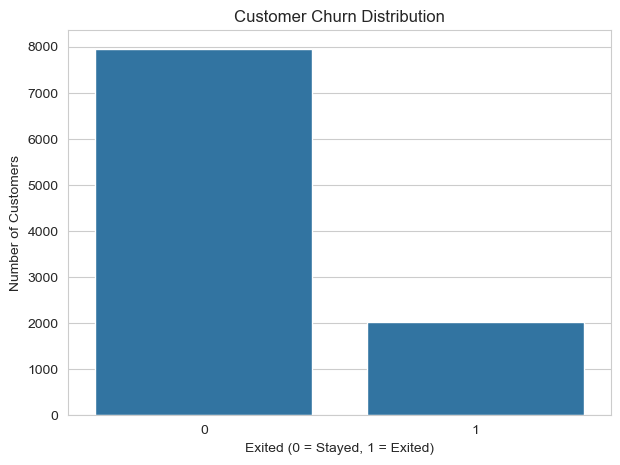

In [5]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='Exited')

plt.title('Customer Churn Distribution')
plt.xlabel('Exited (0 = Stayed, 1 = Exited)')
plt.ylabel('Number of Customers')

plt.show()

In [14]:
churn_percentage = df['Exited'].value_counts(normalize=True) * 100

print(churn_percentage)

Exited
0    79.63
1    20.37
Name: proportion, dtype: float64


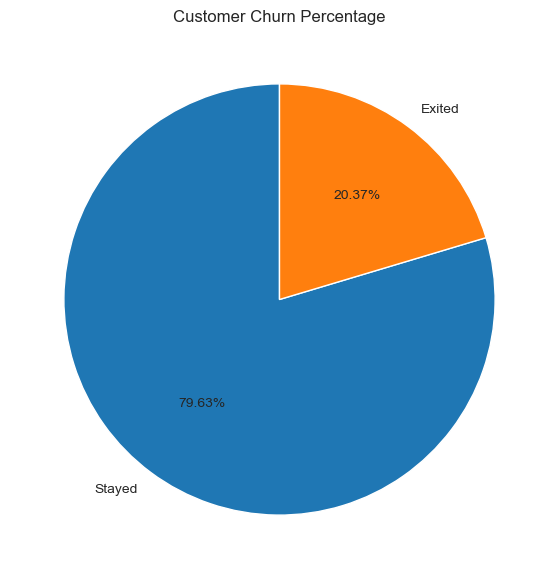

In [16]:
plt.figure(figsize=(7, 7))

plt.pie(
    churn_percentage,
    labels=['Stayed', 'Exited'],
    autopct='%1.2f%%',  #Displays percentages on the chart.
    startangle=90   #Rotates the starting position.
)

plt.title('Customer Churn Percentage')
plt.show()

In [18]:
pd.crosstab(df['Geography'], df['Exited'])   
# It creates a frequency table showing the relationship between two categorical variables.
#  pd.crosstab() is very similar to an Excel Pivot Table.

Exited,0,1
Geography,,
France,4204,810
Germany,1695,814
Spain,2064,413


In [20]:
# for percentage

pd.crosstab(
    df['Geography'],
    df['Exited'],
    normalize='index'
) * 100

Exited,0,1
Geography,,
France,83.845233,16.154767
Germany,67.556796,32.443204
Spain,83.326605,16.673395


### Germany has the highest churn rate (32.44%).

Observations:
- Germany's churn rate is almost twice that of France and Spain.
- France and Spain have relatively similar churn rates.
- Geography may be an important feature for predicting customer churn.

Remember: This shows an association, not proof that geography causes customers to leave.

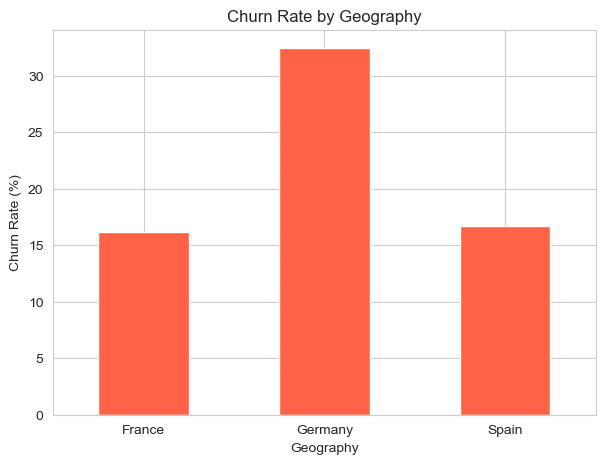

In [21]:
churn_geo = pd.crosstab(
    df['Geography'],
    df['Exited'],
    normalize='index'
) * 100

churn_geo[1].plot(
    kind='bar',
    figsize=(7, 5),
    color='tomato'
)

plt.title('Churn Rate by Geography')
plt.xlabel('Geography')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=0)
plt.show()

In [22]:
pd.crosstab(df['Gender'], df['Exited'])

Exited,0,1
Gender,,
Female,3404,1139
Male,4559,898


In [23]:
pd.crosstab(
    df['Gender'],
    df['Exited'],
    normalize='index'
) * 100

Exited,0,1
Gender,,
Female,74.928461,25.071539
Male,83.544072,16.455928


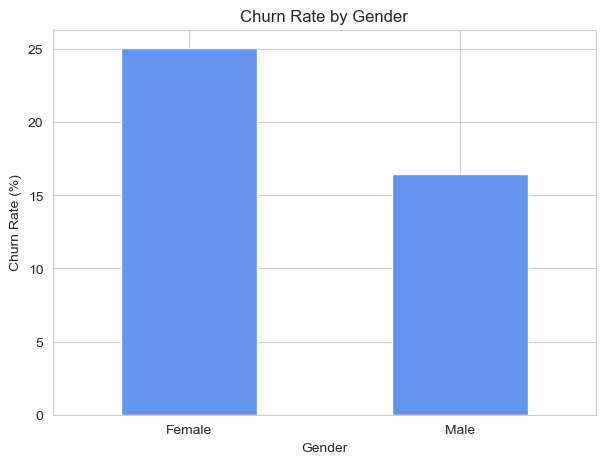

In [24]:
churn_gender = pd.crosstab(
    df['Gender'],
    df['Exited'],
    normalize='index'
) * 100

churn_gender[1].plot(
    kind='bar',
    figsize=(7, 5),
    color='cornflowerblue'
)

plt.title('Churn Rate by Gender')
plt.xlabel('Gender')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=0)
plt.show()

In [25]:
df.groupby('Exited')['Age'].mean()

Exited
0    37.408389
1    44.837997
Name: Age, dtype: float64

1. Interpretation — Average Age vs Churn
Customer Type	Average Age
- Stayed (0) |	37.41 years
- Exited (1)|	44.84 years

Key observations:
- Customers who exited are older on average.
- The average age difference is approximately 7.43 years.
- Age may be an important predictor of customer churn.
This suggests that older customers in this dataset are more likely to leave, but it does not establish causation.

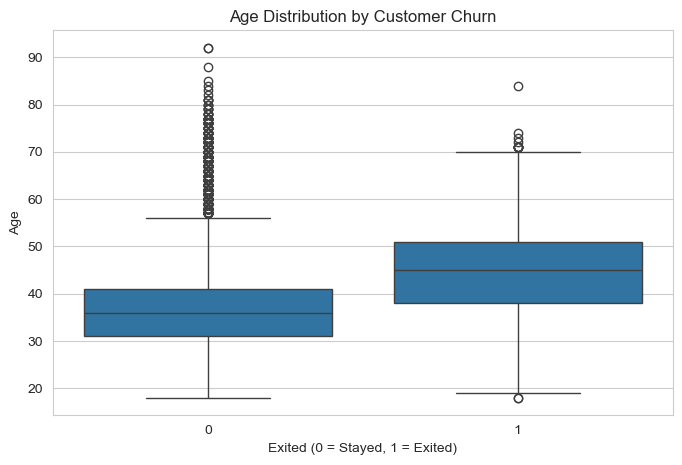

In [26]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='Exited',
    y='Age'
)

plt.title('Age Distribution by Customer Churn')
plt.xlabel('Exited (0 = Stayed, 1 = Exited)')
plt.ylabel('Age')

plt.show()

In [27]:
pd.crosstab(
    df['NumOfProducts'],
    df['Exited']
)

Exited,0,1
NumOfProducts,,
1,3675,1409
2,4242,348
3,46,220
4,0,60


In [28]:
pd.crosstab(
    df['NumOfProducts'],
    df['Exited'],
    normalize='index'
) * 100

Exited,0,1
NumOfProducts,,
1,72.285602,27.714398
2,92.418301,7.581699
3,17.293233,82.706767
4,0.000000,100.000000


Key observations:
- Customers using 1 product have 1,409 exits.
- Customers using 2 products have comparatively fewer exits (348).
- Customers using 3 products show a high number of exits relative to their group size.
- All 60 customers using 4 products exited in this dataset.

Notice that the number of customers using 3 and 4 products is much smaller. So, we must compare churn percentages rather than raw counts.

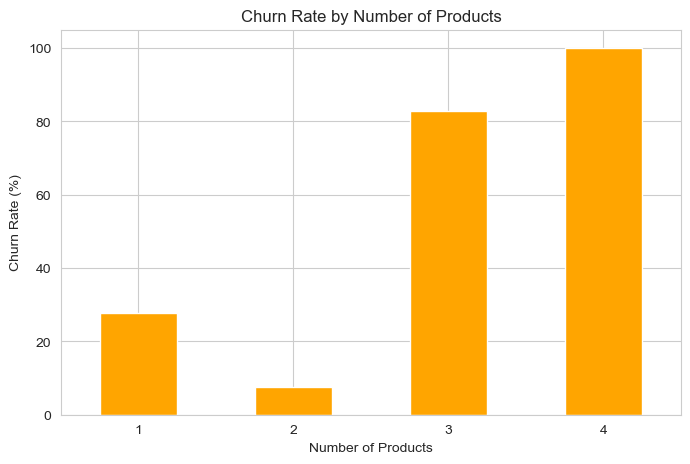

In [29]:
churn_products = pd.crosstab(
    df['NumOfProducts'],
    df['Exited'],
    normalize='index'
) * 100

churn_products[1].plot(
    kind='bar',
    figsize=(8, 5),
    color='orange'
)

plt.title('Churn Rate by Number of Products')
plt.xlabel('Number of Products')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=0)
plt.show()


In [30]:
pd.crosstab(
    df['IsActiveMember'],
    df['Exited']
)

Exited,0,1
IsActiveMember,,
0,3547,1302
1,4416,735


In [31]:
pd.crosstab(
    df['IsActiveMember'],
    df['Exited'],
    normalize='index'
) * 100

Exited,0,1
IsActiveMember,,
0,73.149103,26.850897
1,85.730926,14.269074


Key findings:
- Inactive customers have a higher churn rate (26.85%).
- Active customers have a lower churn rate (14.27%).
- Inactive customers are approximately 1.88 times as likely to churn as active customers, based on these observed rates.

Conclusion: Active membership appears to be an important feature associated with customer retention.

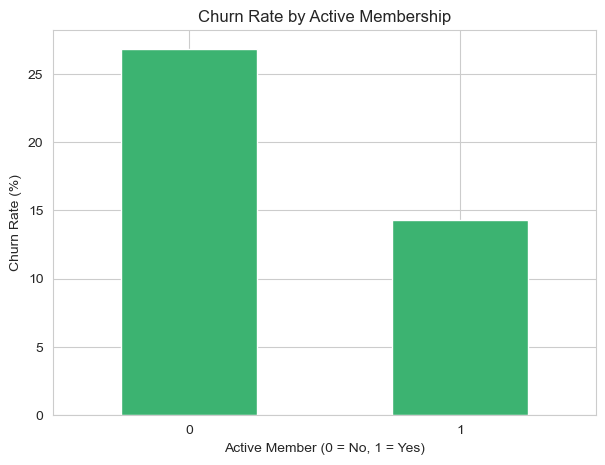

In [32]:
churn_active = pd.crosstab(
    df['IsActiveMember'],
    df['Exited'],
    normalize='index'
) * 100

churn_active[1].plot(
    kind='bar',
    figsize=(7, 5),
    color='mediumseagreen'
)

plt.title('Churn Rate by Active Membership')
plt.xlabel('Active Member (0 = No, 1 = Yes)')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=0)
plt.show()

In [36]:
df.groupby('Exited')['CreditScore'].mean()

#- The difference is only about 6.50 points.
#This suggests that the average credit score difference between the two groups is relatively small. We cannot conclude that CreditScore is unimportant from averages alone.

Exited
0    651.853196
1    645.351497
Name: CreditScore, dtype: float64

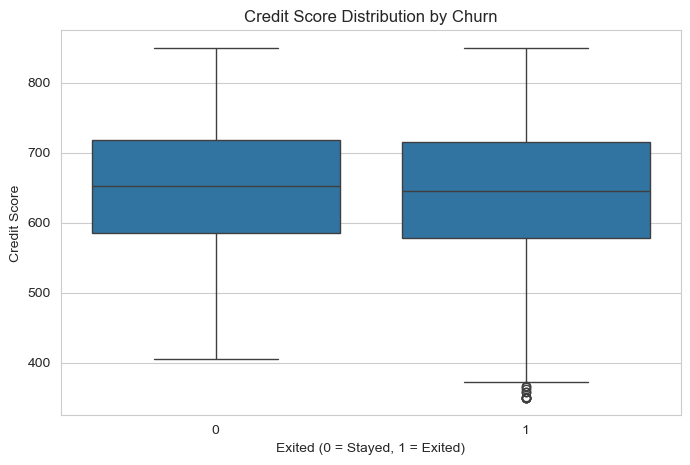

In [34]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='Exited',
    y='CreditScore'
)

plt.title('Credit Score Distribution by Churn')
plt.xlabel('Exited (0 = Stayed, 1 = Exited)')
plt.ylabel('Credit Score')

plt.show()

In [38]:
df.groupby('Exited')['Tenure'].mean

# The difference is only 0.10 years, which is very small.
# This suggests that average tenure alone may not strongly distinguish customers who churn from those who stay.

<bound method GroupBy.mean of <pandas.core.groupby.generic.SeriesGroupBy object at 0x0000026227022E10>>

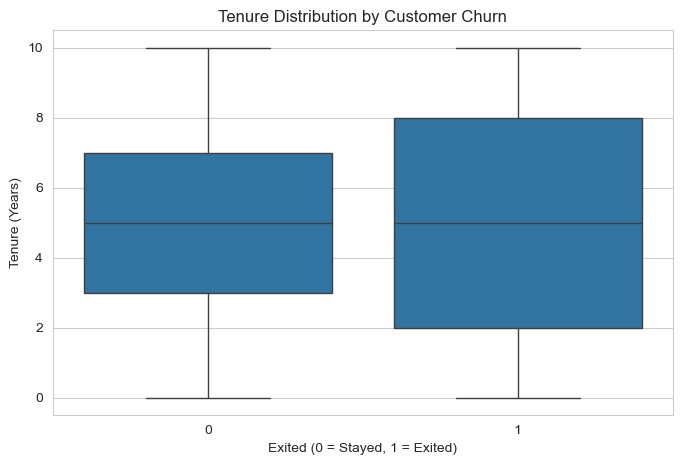

In [39]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='Exited',
    y='Tenure'
)

plt.title('Tenure Distribution by Customer Churn')
plt.xlabel('Exited (0 = Stayed, 1 = Exited)')
plt.ylabel('Tenure (Years)')

plt.show()

In [40]:
df.groupby('Exited')['Balance'].mean()

Exited
0    72745.296779
1    91108.539337
Name: Balance, dtype: float64

Key observations:
- Customers who exited had a higher average bank balance.
- The difference is approximately ₹18,363.24.
- Customers with higher balances appear more likely to churn in this dataset.

However, average balance alone does not prove that higher balances cause churn.

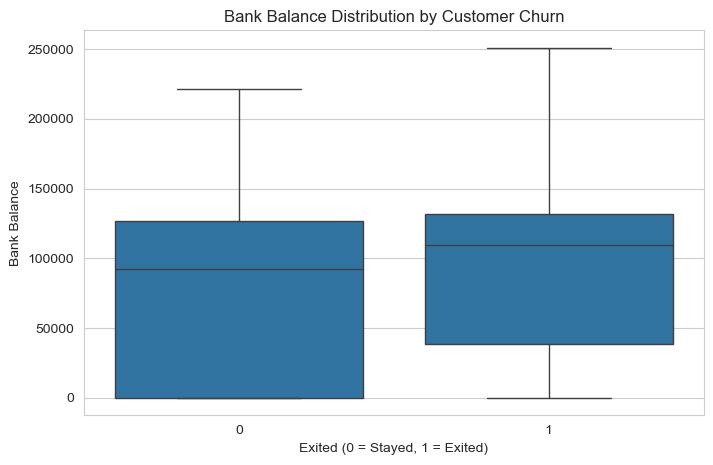

In [41]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='Exited',
    y='Balance'
)

plt.title('Bank Balance Distribution by Customer Churn')
plt.xlabel('Exited (0 = Stayed, 1 = Exited)')
plt.ylabel('Bank Balance')

plt.show()

In [42]:
df.groupby('Exited')['EstimatedSalary'].mean()

Exited
0     99738.391772
1    101465.677531
Name: EstimatedSalary, dtype: float64

Observations:
- Customers who exited have a slightly higher average estimated salary.
- The difference is approximately 1,727.29.
- The difference is relatively small compared with the overall salary values.

This suggests that average estimated salary alone may not be a strong indicator of churn

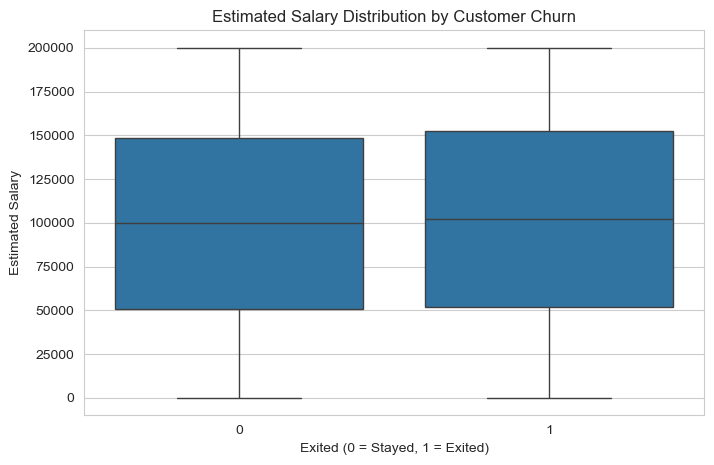

In [43]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='Exited',
    y='EstimatedSalary'
)

plt.title('Estimated Salary Distribution by Customer Churn')
plt.xlabel('Exited (0 = Stayed, 1 = Exited)')
plt.ylabel('Estimated Salary')

plt.show()

In [44]:
correlation = df.corr(numeric_only=True)

correlation

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
CreditScore,1.000000,-0.003965,0.000842,0.006268,0.012238,-0.005458,0.025651,-0.001384,-0.027094
Age,-0.003965,1.000000,-0.009997,0.028308,-0.030680,-0.011721,0.085472,-0.007201,0.285323
Tenure,0.000842,-0.009997,1.000000,-0.012254,0.013444,0.022583,-0.028362,0.007784,-0.014001
Balance,0.006268,0.028308,-0.012254,1.000000,-0.304180,-0.014858,-0.010084,0.012797,0.118533
NumOfProducts,0.012238,-0.030680,0.013444,-0.304180,1.000000,0.003183,0.009612,0.014204,-0.047820
HasCrCard,-0.005458,-0.011721,0.022583,-0.014858,0.003183,1.000000,-0.011866,-0.009933,-0.007138
IsActiveMember,0.025651,0.085472,-0.028362,-0.010084,0.009612,-0.011866,1.000000,-0.011421,-0.156128
EstimatedSalary,-0.001384,-0.007201,0.007784,0.012797,0.014204,-0.009933,-0.011421,1.000000,0.012097
Exited,-0.027094,0.285323,-0.014001,0.118533,-0.047820,-0.007138,-0.156128,0.012097,1.000000


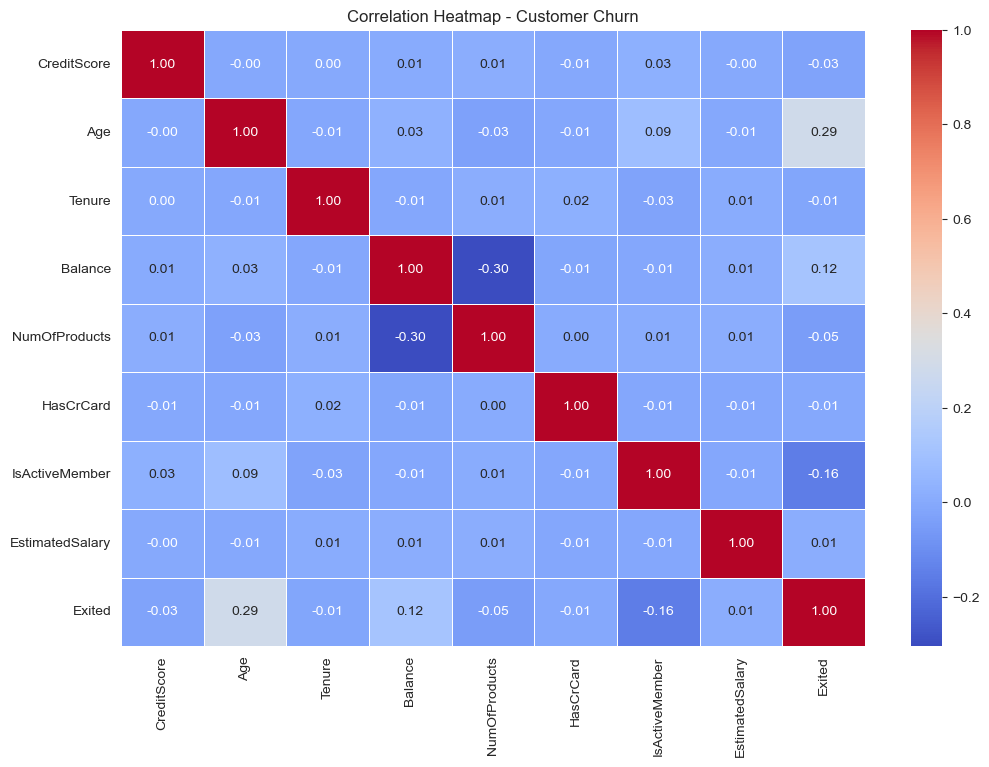

In [45]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap - Customer Churn')
plt.show()

### Important observations
1. Age (+0.2853)

Age has the strongest positive linear correlation with churn among these features. Older customers tend to have a higher likelihood of exiting.

2. IsActiveMember (-0.1561)

Negative correlation means active membership is associated with lower churn.

3. Balance (+0.1185)

Customers with higher balances tend to show somewhat higher churn.

4. EstimatedSalary (+0.0121)

Almost zero linear correlation with churn.

Important: Correlation does not establish causation. Also, a weak correlation does not necessarily mean a feature is useless for machine learning. Nonlinear relationships may exist.

In [46]:
pd.crosstab(
    df['HasCrCard'],
    df['Exited']
)

Exited,0,1
HasCrCard,,
0,2332,613
1,5631,1424


In [47]:
pd.crosstab(
    df['HasCrCard'],
    df['Exited'],
    normalize='index'
) * 100

Exited,0,1
HasCrCard,,
0,79.185059,20.814941
1,79.815734,20.184266


In [48]:
# Conclusion: Having a credit card does not show a substantial difference in churn rate in this dataset.

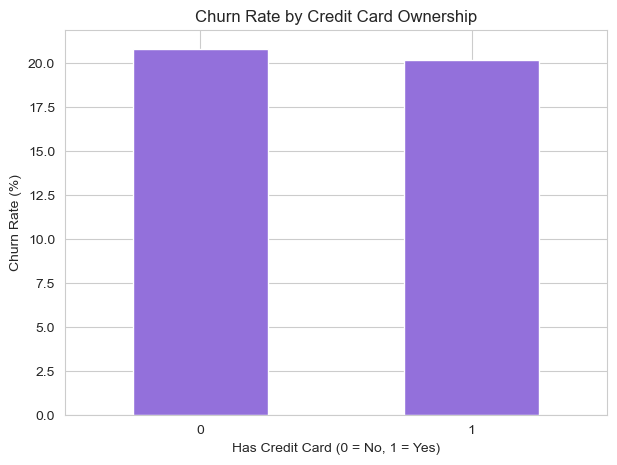

In [49]:
churn_card = pd.crosstab(
    df['HasCrCard'],
    df['Exited'],
    normalize='index'
) * 100

churn_card[1].plot(
    kind='bar',
    figsize=(7, 5),
    color='mediumpurple'
)

plt.title('Churn Rate by Credit Card Ownership')
plt.xlabel('Has Credit Card (0 = No, 1 = Yes)')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=0)
plt.show()

In [50]:
pd.crosstab(
    [df['Geography'], df['Gender']],
    df['Exited'],
    normalize='index'
) * 100

Exited                    0          1
Geography Gender                      
France    Female  79.655020  20.344980
          Male    87.286596  12.713404
Germany   Female  62.447611  37.552389
          Male    72.188450  27.811550
Spain     Female  78.787879  21.212121
          Male    86.887608  13.112392

## Final EDA Findings

1. **Target Distribution:** 20.37% customers exited, indicating moderate class imbalance.

2. **Geography:** Germany has the highest churn rate (32.44%).

3. **Gender:** Female customers have a higher churn rate (25.07%) than male customers (16.46%).

4. **Age:** Customers who exited have a higher average age (44.84 years) than customers who stayed (37.41 years).

5. **Number of Products:** Customers with 3 or 4 products show very high churn rates. However, these groups have relatively few records.

6. **Active Membership:** Inactive customers have a higher churn rate (26.85%) than active customers (14.27%).

7. **Balance:** Customers who exited have a higher average balance.

8. **Correlation:** Age has the strongest positive correlation with churn (0.285), while active membership has a negative correlation (-0.156).

9. **Credit Card and Salary:** These features show very little difference in churn behaviour.

### Conclusion

EDA helped identify important customer characteristics associated with churn. Age, Geography, Gender, Number of Products and Active Membership show meaningful patterns.

The dataset is ready for Feature Engineering and Machine Learning preparation.